# Probabilistic SMS Spam Detection
**Course:** BAMAT207 Probability and Statistics - Project Activity
**Topic:** Probability and Random Variables

This notebook classifies an SMS message as **Spam** or **Ham** (genuine) using:
dataset analysis, conditional probability, Bayes' theorem, expectation and variance of a random variable,
and a Multinomial Naive Bayes classifier.

In [1]:
import io
import re
import urllib.request
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report

DATA_FILE = Path("data/SMSSpamCollection")
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

RANDOM_STATE = 42
TEST_SIZE = 0.20
SUSPICIOUS_WORDS = ["free", "prize", "win", "urgent", "offer"]

## 1. Dataset Handling
Dataset: **SMS Spam Collection** (UCI Machine Learning Repository, 5,574 labelled messages).

Note: `ucimlrepo.fetch_ucirepo(id=228)` reports that this dataset is *not available for import*,
so the official UCI zip file is downloaded directly instead (and kept in `data/` so it also works offline).

In [2]:
def load_dataset():
    if not DATA_FILE.exists():
        DATA_FILE.parent.mkdir(exist_ok=True)
        with urllib.request.urlopen(DATA_URL) as response:
            archive = zipfile.ZipFile(io.BytesIO(response.read()))
        archive.extract("SMSSpamCollection", DATA_FILE.parent)
    # The file is tab separated: label <TAB> message. quoting=3 keeps quote characters as plain text.
    return pd.read_csv(DATA_FILE, sep="\t", header=None, names=["label", "message"], quoting=3)


df = load_dataset()
print("Messages loaded:", len(df))
df.head()

Messages loaded: 5574


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [3]:
print("Missing values per column:")
print(df.isnull().sum())

rows_before = len(df)
df = df.drop_duplicates(subset="message").reset_index(drop=True)
print("\nDuplicate messages removed:", rows_before - len(df))
print("Messages after cleaning:", len(df))

# Spam = 1, Ham = 0
df["label_num"] = df["label"].map({"spam": 1, "ham": 0})
df.head()

Missing values per column:
label      0
message    0
dtype: int64

Duplicate messages removed: 403
Messages after cleaning: 5171


,label,message,label_num
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


## 2. Dataset Analysis
P(Spam) = spam messages / total messages, P(Ham) = ham messages / total messages

In [4]:
total = len(df)
n_spam = int((df["label_num"] == 1).sum())
n_ham = int((df["label_num"] == 0).sum())

p_spam = n_spam / total
p_ham = n_ham / total

print("Cleaned dataset summary")
print("Total messages :", total)
print("Spam messages  :", n_spam)
print("Ham messages   :", n_ham)
print(f"P(Spam) = {n_spam}/{total} = {p_spam:.4f}")
print(f"P(Ham)  = {n_ham}/{total} = {p_ham:.4f}")
print("Check: P(Spam) + P(Ham) =", round(p_spam + p_ham, 4))

Cleaned dataset summary
Total messages : 5171
Spam messages  : 653
Ham messages   : 4518
P(Spam) = 653/5171 = 0.1263
P(Ham)  = 4518/5171 = 0.8737
Check: P(Spam) + P(Ham) = 1.0


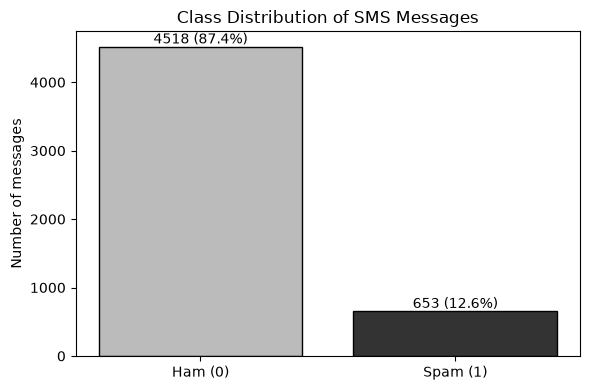

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Ham (0)", "Spam (1)"], [n_ham, n_spam], color=["#bbbbbb", "#333333"], edgecolor="black")
ax.bar_label(bars, labels=[f"{n_ham} ({p_ham:.1%})", f"{n_spam} ({p_spam:.1%})"])
ax.set_title("Class Distribution of SMS Messages")
ax.set_ylabel("Number of messages")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150)
plt.show()

## 3. Word-Based Probability Analysis
For each suspicious word W:

- Direct count: P(Spam | W) = spam messages containing W / all messages containing W
- Bayes' theorem: P(Spam | W) = P(W | Spam) x P(Spam) / P(W)

Both methods must give the same answer. A word is matched as a whole word, ignoring case.

In [6]:
def contains_word(messages, word):
    pattern = rf"\b{re.escape(word)}\b"
    return messages.str.contains(pattern, case=False, regex=True)


rows = []
for word in SUSPICIOUS_WORDS:
    has_word = contains_word(df["message"], word)
    n_word = int(has_word.sum())
    n_spam_word = int((has_word & (df["label_num"] == 1)).sum())

    direct = n_spam_word / n_word
    p_word_given_spam = n_spam_word / n_spam
    p_word = n_word / total
    bayes = p_word_given_spam * p_spam / p_word

    rows.append({
        "word": word,
        "messages with word": n_word,
        "spam with word": n_spam_word,
        "P(W|Spam)": round(p_word_given_spam, 4),
        "P(W)": round(p_word, 4),
        "P(Spam|W) direct": round(direct, 4),
        "P(Spam|W) Bayes": round(bayes, 4),
    })

word_table = pd.DataFrame(rows)
word_table

,word,messages with word,spam with word,P(W|Spam),P(W),P(Spam|W) direct,P(Spam|W) Bayes
0,free,203,148,0.2266,0.0393,0.7291,0.7291
1,prize,73,73,0.1118,0.0141,1.0000,1.0000
2,win,55,49,0.0750,0.0106,0.8909,0.8909
3,urgent,62,57,0.0873,0.0120,0.9194,0.9194
4,offer,30,24,0.0368,0.0058,0.8000,0.8000


In [7]:
# Worked example for the word "free"
free = word_table.set_index("word").loc["free"]
print("Direct  : P(Spam|free) =", int(free["spam with word"]), "/", int(free["messages with word"]),
      "=", free["P(Spam|W) direct"])
print("Bayes   : P(Spam|free) = P(free|Spam) x P(Spam) / P(free)")
print(f"          = {free['P(W|Spam)']} x {p_spam:.4f} / {free['P(W)']} = {free['P(Spam|W) Bayes']}")

Direct  : P(Spam|free) = 148 / 203 = 0.7291
Bayes   : P(Spam|free) = P(free|Spam) x P(Spam) / P(free)
          = 0.2266 x 0.1263 / 0.0393 = 0.7291


## 4. Random Variable Analysis
Y = 1 if the message is spam, Y = 0 if it is ham. Y is a **Bernoulli** random variable with p = P(Spam).

- E(Y) = 1 x p + 0 x (1 - p) = p
- Var(Y) = E(Y^2) - [E(Y)]^2 = p - p^2 = p(1 - p)

In [8]:
Y = df["label_num"].to_numpy()
p = p_spam

expected_formula = p
variance_formula = p * (1 - p)

print(f"E(Y)   formula  = p          = {expected_formula:.4f}")
print(f"E(Y)   numpy    = mean(Y)    = {np.mean(Y):.4f}")
print(f"Var(Y) formula  = p(1 - p)   = {variance_formula:.4f}")
print(f"Var(Y) numpy    = var(Y)     = {np.var(Y):.4f}")
print(f"Std(Y)          = sqrt(Var)  = {np.sqrt(variance_formula):.4f}")

E(Y)   formula  = p          = 0.1263
E(Y)   numpy    = mean(Y)    = 0.1263
Var(Y) formula  = p(1 - p)   = 0.1103
Var(Y) numpy    = var(Y)     = 0.1103
Std(Y)          = sqrt(Var)  = 0.3322


## 5. Data Preparation
80% training / 20% testing with **stratified** sampling, so both parts keep the same spam-ham ratio.
`CountVectorizer` turns each message into word counts. It is fitted on the training data only.

In [9]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df["message"], df["label_num"],
    test_size=TEST_SIZE, stratify=df["label_num"], random_state=RANDOM_STATE,
)

print("Training messages:", len(X_train_text), f"(spam share {y_train.mean():.4f})")
print("Testing messages :", len(X_test_text), f"(spam share {y_test.mean():.4f})")

vectorizer = CountVectorizer(lowercase=True)
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)
print("Vocabulary size (number of word features):", len(vectorizer.vocabulary_))

Training messages: 4136 (spam share 0.1262)
Testing messages : 1035 (spam share 0.1266)
Vocabulary size (number of word features): 7669


## 6. Model Building
Multinomial Naive Bayes uses Bayes' theorem with the "naive" assumption that words are independent given the class.
It works well with word counts.

In [10]:
model = MultinomialNB()
model.fit(X_train, y_train)

print("Prior P(Ham), P(Spam) learned from training data:", np.round(np.exp(model.class_log_prior_), 4))

Prior P(Ham), P(Spam) learned from training data: [0.8738 0.1262]


## 7. Model Evaluation
Accuracy, Precision, Recall, F1-score and the Confusion Matrix on the 20% test set.

In [11]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}\n")
report = classification_report(y_test, y_pred, target_names=["Ham", "Spam"], digits=4)
print(report)

cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
print(f"\nSpam messages incorrectly classified as genuine (False Negatives): {fn}")
print(f"Genuine messages incorrectly classified as spam (False Positives): {fp}")

Accuracy: 0.9807

              precision    recall  f1-score   support

         Ham     0.9846    0.9934    0.9890       904
        Spam     0.9512    0.8931    0.9213       131

    accuracy                         0.9807      1035
   macro avg     0.9679    0.9432    0.9551      1035
weighted avg     0.9804    0.9807    0.9804      1035

Confusion matrix [[TN, FP], [FN, TP]]:
[[898   6]
 [ 14 117]]

Spam messages incorrectly classified as genuine (False Negatives): 14
Genuine messages incorrectly classified as spam (False Positives): 6


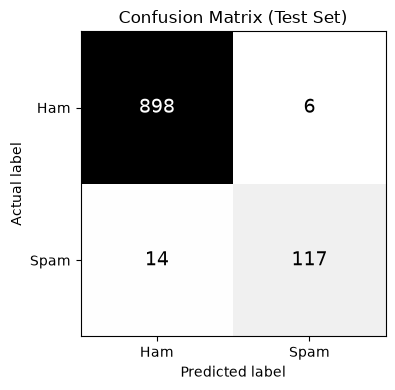

In [12]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap="Greys")
labels = ["Ham", "Spam"]
ax.set_xticks([0, 1], labels=labels)
ax.set_yticks([0, 1], labels=labels)
ax.set_xlabel("Predicted label")
ax.set_ylabel("Actual label")
ax.set_title("Confusion Matrix (Test Set)")
for i in range(2):
    for j in range(2):
        text_color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14, color=text_color)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

In [13]:
test_results = pd.DataFrame({"message": X_test_text, "actual": y_test, "predicted": y_pred})

print("Spam predicted as Ham (missed spam):")
for msg in test_results.query("actual == 1 and predicted == 0")["message"].head(5):
    print(" -", msg)

print("\nHam predicted as Spam (false alarm):")
for msg in test_results.query("actual == 0 and predicted == 1")["message"].head(5):
    print(" -", msg)

Spam predicted as Ham (missed spam):
 - Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
 - Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner
 - Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. They're selling fast!
 - Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
 - Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs)

Ham predicted as Spam (false alarm):
 - Nokia phone is lovly..
 - Have you laid your airtel line to rest?
 - I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to  &lt;#&gt;
 - Unlimited texts. Limited minutes.
 - Mostly sports type..lyk footbl,crckt..


## 8. Real-Time Testing
`predict_message` returns the predicted class and the probabilities P(Spam | Message) and P(Ham | Message).

In [14]:
def predict_message(message):
    features = vectorizer.transform([message])
    p_ham_msg, p_spam_msg = model.predict_proba(features)[0]
    prediction = "Spam" if p_spam_msg >= 0.5 else "Ham (Genuine)"
    print("Message:", message)
    print("Prediction:", prediction)
    print(f"P(Spam | Message) = {p_spam_msg:.4f}")
    print(f"P(Ham | Message) = {p_ham_msg:.4f}\n")
    return prediction, p_spam_msg, p_ham_msg


predict_message("Congratulations! You have won a free prize. Claim now.")
predict_message("Hey, are we still meeting for lunch at 1 today?")
predict_message("URGENT! Your mobile number has been selected for a cash offer. Call now.")

Message: Congratulations! You have won a free prize. Claim now.
Prediction: Spam
P(Spam | Message) = 1.0000
P(Ham | Message) = 0.0000

Message: Hey, are we still meeting for lunch at 1 today?
Prediction: Ham (Genuine)
P(Spam | Message) = 0.0000
P(Ham | Message) = 1.0000

Message: URGENT! Your mobile number has been selected for a cash offer. Call now.
Prediction: Spam
P(Spam | Message) = 1.0000
P(Ham | Message) = 0.0000



('Spam', np.float64(0.9999996160655966), np.float64(3.8393439789394723e-07))

In [15]:
# Type your own SMS here and run this cell
my_message = "Reminder: your library book is due tomorrow."
predict_message(my_message);

Message: Reminder: your library book is due tomorrow.
Prediction: Ham (Genuine)
P(Spam | Message) = 0.2165
P(Ham | Message) = 0.7835



In [16]:
# Save a short text summary of all results
with open(OUTPUT_DIR / "results.txt", "w", encoding="utf-8") as f:
    f.write("Probabilistic SMS Spam Detection - Results\n\n")
    f.write(f"Messages after cleaning: {total} (spam {n_spam}, ham {n_ham})\n")
    f.write(f"P(Spam) = {p_spam:.4f}, P(Ham) = {p_ham:.4f}\n")
    f.write(f"E(Y) = {expected_formula:.4f}, Var(Y) = {variance_formula:.4f}\n\n")
    f.write(word_table.to_string(index=False) + "\n\n")
    f.write(f"Accuracy: {accuracy:.4f}\n\n{report}\n")
    f.write(f"Confusion matrix [[TN, FP], [FN, TP]]:\n{cm}\n")
print("Saved outputs/results.txt")

Saved outputs/results.txt
